# Infield Throw Performance Project - Exploratory Data Analysis
**By:** Marchiano Oh (marchiano.oh@gmail.com)

**Notebook Contents:**
* [Exploratory Data Analysis](#Exploratory-Data-Analysis)
    * [Check Data Types and Values](#Check-Data-Types-and-Values)
    * [Missing Values Investigation](#Missing-Values-Investigation)
    * [Feature Cardinality Check](#Feature-Cardinality-Check)
    * [Unique Values and Value Counts](#Unique-Values-and-Value-Counts)
    * [Describe Features](#Describe-Features)
    * [Outliers](#Outliers)
    * [Position Coordinate Data Visualization](#Position-Coordinate-Data-Visualization)

## Exploratory Data Analysis

In [2]:
# Import necessary Python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [3]:
# Import the dataset
working_directory = 'C:\\Users\\Marchiano\\Documents\\Infield Throw Performance Project\\'

fielder_throws_df = pd.read_csv(working_directory + 'dataset_2026.csv', header=0)

# Show snippet of dataset to preview data and verify import was done 
fielder_throws_df.head()

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
0,3,11,400,6,400,6,63,3,1.533,-60.116123,...,-25.452504,7.330194,56.199323,60.187776,8.202015,0,____1,1___1,0,first
1,6,11,228,5,390,4,63,3,0.534,-0.562563,...,NaN,NaN,59.013134,65.657938,5.047566,0,1___1,1___2,0,first
2,7,8,415,4,415,4,143,3,1.266,1.598751,...,NaN,NaN,61.037489,64.429134,2.719261,0,123_1,____3,0,out
3,8,8,308,1,308,1,143,3,1.800,25.403185,...,NaN,NaN,63.142075,65.648720,2.069797,0,____1,____2,0,out
4,10,1,314,4,300,6,514,3,0.733,8.957441,...,NaN,NaN,59.770395,64.046058,3.890504,0,123_1,____3,0,out


[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Check Data Types and Values 

In [4]:
# Check dataset size
fielder_throws_df.shape

(20000, 30)

In [5]:
# Check data types of dataset features
fielder_throws_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   throw_id                     20000 non-null  int64  
 1   team_id                      20000 non-null  int64  
 2   fielder_id                   20000 non-null  int64  
 3   fielder_position             20000 non-null  int64  
 4   thrower_id                   20000 non-null  int64  
 5   thrower_position             20000 non-null  int64  
 6   receiver_id                  20000 non-null  int64  
 7   receiver_position            20000 non-null  int64  
 8   exchange_time                19993 non-null  float64
 9   throw_pos_x                  19987 non-null  float64
 10  throw_pos_y                  19987 non-null  float64
 11  throw_velo_x                 19988 non-null  float64
 12  throw_velo_y                 19988 non-null  float64
 13  throw_velo_z    

The dataset has all numerical features except for `start_state`, `end_state`, and `batter_result`, which are all of type object (string).
All the data types in the dataset make sense within a baseball context.

In [6]:
# Check if the dataset has duplicate rows
if fielder_throws_df.duplicated().sum() == 0:
    print("Dataset has no duplicate rows.")
else:
    print("Dataset has duplicate rows to be found.")

Dataset has no duplicate rows.


[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Missing Values Investigation
Looking into the missing values of the dataset and their reason why and deciding on what action to take

In [7]:
# Check for the number of 'NA' values in each feature in the dataset
throws_nacount_series = fielder_throws_df.isna().sum()
throws_nacount_series

throw_id                           0
team_id                            0
fielder_id                         0
fielder_position                   0
thrower_id                         0
thrower_position                   0
receiver_id                        0
receiver_position                  0
exchange_time                      7
throw_pos_x                       13
throw_pos_y                       13
throw_velo_x                      12
throw_velo_y                      12
throw_velo_z                      12
batter_pos_x_at_throw             30
batter_pos_y_at_throw             30
batter_velo_at_throw              30
bounce_pos_x                   18109
bounce_pos_y                   18109
bounce_velo_x                  18109
bounce_velo_y                  18109
bounce_velo_z                  18109
receiver_pos_x                    32
receiver_pos_y                    32
receiver_dist_from_1b             32
throw_deflected_by_receiver        0
start_state                        0
e

`NA` values are valid in the `bounce_pos_x`, `bounce_pos_y`, `bounce_velo_x`, `bounce_velo_y`, and `bounce_velo_z` columns because they mean no bounce was detected. In high-level baseball, fielder throws to first typically occur without a bounce. Therefore, rows with `NA` values in those columns will be kept.

`NA` values in other columns require more investigation to determine if they are valid or should be removed or replaced.

In [8]:
# Get the rows where the exchange_time was 'NA'
fielder_throws_df.query("exchange_time.isna()")

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
6123,10161,1,813,6,813,6,451,3,NaN,-11.344849,...,NaN,NaN,61.520805,64.723817,2.380093,0,____1,____2,0,out
6771,11263,2,394,6,297,4,695,3,NaN,-0.988650,...,NaN,NaN,59.747938,65.167303,4.180784,0,1___1,____3,0,out
8183,13623,11,655,6,655,6,729,3,NaN,-22.759851,...,NaN,NaN,61.447542,66.432250,3.550212,0,_2__2,____3,0,out
11214,18571,9,269,6,269,6,403,3,NaN,32.039704,...,NaN,NaN,60.476463,63.447873,3.168953,0,_2__2,____3,0,out
11483,19005,3,92,4,92,4,103,3,NaN,46.832340,...,NaN,NaN,60.437752,64.468515,3.307412,0,____0,____1,0,out
13463,22350,10,391,6,391,6,50,3,NaN,-41.565022,...,NaN,NaN,62.073770,66.062556,2.884878,0,____0,____1,0,out
14084,23365,2,43,1,43,1,605,3,NaN,14.633763,...,NaN,NaN,61.512440,63.691246,2.127797,0,1___2,____3,0,out


In [9]:
# Get the rows where the exchange_time was 'NA' with throw velocity columns to verify that a throw was recorded for these rows
fielder_throws_df[['exchange_time', 'fielder_position', 'thrower_position', 'receiver_position', 'throw_velo_x', 'throw_velo_y',
                   'throw_velo_z', 'start_state', 'end_state', 'batter_result']].query("exchange_time.isna()")

,exchange_time,fielder_position,thrower_position,receiver_position,throw_velo_x,throw_velo_y,throw_velo_z,start_state,end_state,batter_result
6123,NaN,6,6,3,67.616395,-49.945510,5.643536,____1,____2,out
6771,NaN,6,4,3,56.743117,-48.228889,8.573584,1___1,____3,out
8183,NaN,6,6,3,61.593926,-46.197468,10.022479,_2__2,____3,out
11214,NaN,6,6,3,-45.561209,-13.646046,9.915777,_2__2,____3,out
11483,NaN,4,4,3,9.572674,-52.105400,10.913324,____0,____1,out
13463,NaN,6,6,3,67.448226,-37.689198,10.194990,____0,____1,out
14084,NaN,1,1,3,34.555782,1.350858,9.646555,1___2,____3,out


Seeing how in row 6771 (second row from the above result) a 6-4-3 double play occurred but there is no `exchange_time` value, 
it is prudent to verify if an `exchange_time` value is recorded or if it is `NA` for instances where the fielder and thrower are different. The difference in fielder and thrower is likely from double play attempts or fielding assists.

In [10]:
# Check if there are 'NA' for exchange_time in instances where the fielder and thrower are different
different_fielder_thrower_df = fielder_throws_df[['exchange_time', 'fielder_position', 'thrower_position', 'receiver_position', 'throw_velo_x',
                                                  'throw_velo_y', 'throw_velo_z', 'start_state', 'end_state', 'batter_result']].query("fielder_position != thrower_position")
different_fielder_thrower_df

,exchange_time,fielder_position,thrower_position,receiver_position,throw_velo_x,throw_velo_y,throw_velo_z,start_state,end_state,batter_result
1,0.534,5,4,3,51.293917,-45.316519,8.831870,1___1,1___2,first
4,0.733,4,6,3,51.630666,-63.361730,7.811719,123_1,____3,out
9,0.366,6,4,3,54.845266,-50.392070,3.521749,1___0,____2,out
24,0.567,3,6,3,50.267763,-49.029030,8.906780,1___1,1___2,first
34,0.566,5,4,3,52.524782,-50.420928,6.171118,1___0,____2,out
...,...,...,...,...,...,...,...,...,...,...
19963,3.266,9,6,3,0.116074,-28.361894,12.068340,____2,_2__2,second
19980,0.700,4,6,3,45.983328,-53.216926,6.687887,1___1,____3,out
19988,0.833,1,6,3,47.217207,-41.797800,6.959626,1___0,____2,out
19995,0.567,6,4,3,53.870710,-48.222079,0.569104,123_1,1_3_2,first


In [11]:
# Calculate the number of `NA` values in exchange_time in instances where the fielder and thrower are different
print(f"In instances where the fielder and thrower are different, there is a total of {different_fielder_thrower_df['exchange_time'].isna().sum()} \
'NA' value(s) in exchange_time. The rows in question are shown below:\n")

# Print the row(s) where the 'NA' values in exchange_time occurs
different_fielder_thrower_df.query("exchange_time.isna()")

In instances where the fielder and thrower are different, there is a total of 1 'NA' value(s) in exchange_time. The rows in question are shown below:



,exchange_time,fielder_position,thrower_position,receiver_position,throw_velo_x,throw_velo_y,throw_velo_z,start_state,end_state,batter_result
6771,NaN,6,4,3,56.743117,-48.228889,8.573584,1___1,____3,out


`exchange_time` values are recorded where the fielder and thrower are different with the exception of row 6771, which was initially found. Thus, row 6771 is interpreted being an anomaly that does not have an `exchange_time` recorded for its throw.

Considering how throw velocity values exist and an out was recorded on all instances where the `exchange_time` is `NA`, this must imply that the exchange time was not recorded or the fielder made the play without making an exchange from the glove to the throwing hand (i.e., barehanded and threw the ball, tossed the ball directly from the glove, or threw the glove with the ball inside to first baseman). These are all plausible baseball plays and thus, the rows with `NA` in `exchange_time` are kept for now and dealt during missing value imputation during modeling.

In [12]:
# Get the rows where the throw_pos_x was 'NA'
fielder_throws_df.query("throw_pos_x.isna()")

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
1310,2141,11,228,5,228,5,729,3,1.500,NaN,...,NaN,NaN,62.359271,65.861359,2.564262,0,____0,____1,0,out
3793,6275,1,314,4,314,4,514,3,0.967,NaN,...,NaN,NaN,60.972563,63.483358,2.671621,0,____1,____2,0,out
4486,7439,1,311,9,311,9,309,3,1.167,NaN,...,-37.190618,11.399671,29.881372,35.084037,44.215828,0,12__2,12__2,1,first
4521,7490,4,623,1,623,1,397,3,1.034,NaN,...,NaN,NaN,61.594992,64.377156,2.173577,0,____0,____1,0,out
5863,9729,13,749,6,749,6,675,3,1.033,NaN,...,NaN,NaN,60.524320,64.750855,3.307551,0,____2,____3,0,out
6249,10380,5,320,4,320,4,766,3,1.834,NaN,...,NaN,NaN,60.834341,64.270860,2.875415,0,____1,____2,0,out
6370,10595,1,813,6,813,6,451,3,1.333,NaN,...,-24.877193,9.271379,61.669781,67.547281,4.376084,1,____1,1___1,0,first
6765,11256,5,565,5,565,5,766,3,1.466,NaN,...,NaN,NaN,61.469378,64.752358,2.438876,0,1___2,____3,0,out
7483,12451,13,760,6,760,6,581,3,0.900,NaN,...,NaN,NaN,61.045414,65.417602,3.145014,0,____0,____1,0,out
7783,12940,5,678,5,678,5,766,3,1.233,NaN,...,-13.632802,9.832638,61.235749,65.783641,3.221090,1,____0,1___0,0,first


In [13]:
# See if throw_pos_x and throw_pos_y were both 'NA' in the same rows and whether a throw was recorded for these rows
throw_pos_df = fielder_throws_df[['throw_pos_x', 'throw_pos_y', 'throw_velo_x', 'throw_velo_y', 'throw_velo_z', 'fielder_position', 'thrower_position',
                                  'receiver_position', 'start_state', 'end_state', 'batter_result']].query("throw_pos_x.isna() and throw_pos_y.isna()")
throw_pos_df

,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,fielder_position,thrower_position,receiver_position,start_state,end_state,batter_result
1310,NaN,NaN,73.219138,-14.782276,10.163485,5,5,3,____0,____1,out
3793,NaN,NaN,19.590941,-44.869275,4.011870,4,4,3,____1,____2,out
4486,NaN,NaN,-39.233025,-73.251229,13.106133,9,9,3,12__2,12__2,first
4521,NaN,NaN,29.316640,3.886350,11.231436,1,1,3,____0,____1,out
5863,NaN,NaN,55.078985,-47.821404,3.763359,6,6,3,____2,____3,out
6249,NaN,NaN,14.989048,-62.483403,5.438291,4,4,3,____1,____2,out
6370,NaN,NaN,68.386053,-35.860727,5.791660,6,6,3,____1,1___1,first
6765,NaN,NaN,67.068470,-19.982583,13.021831,5,5,3,1___2,____3,out
7483,NaN,NaN,25.100291,-58.882397,5.502295,6,6,3,____0,____1,out
7783,NaN,NaN,78.823030,-13.028684,7.031290,5,5,3,____0,1___0,first


In [14]:
# Check if dataframe length matches the number of 'NA' values in throw_pos_x and throw_pos_y
print(f"""throw_pos_x 'NA' count: {fielder_throws_df['throw_pos_x'].isna().sum()}
throw_pos_y 'NA' count: {fielder_throws_df['throw_pos_y'].isna().sum()}
Number of rows where both throw_pos_x and throw_pos_y are 'NA': {len(throw_pos_df)}""")

throw_pos_x 'NA' count: 13
throw_pos_y 'NA' count: 13
Number of rows where both throw_pos_x and throw_pos_y are 'NA': 13


`throw_pos_x` and `throw_pos_y` both have 13 `NA` values in the same row as one another but throw velocity data exists for these rows. This likely means that throw position coordinates were not recorded for these 13 throws. If the `fielder_position` was 3 for these instances, it would have meant that the first baseman fielded the ball and tried to record the out without a throw. However, throw velocity data exists and none of the `fielder_position` values is 3 for these rows, meaning a throw occurred and the first baseman did not try to make the play unassisted.

These `NA` values will be kept as they are for now, but will be filled via imputation if these values are needed in further analysis. An option is to drop these rows because they make up less than 0.1% of the entire dataset. However, dropping rows will be the last resort to retain as much of the data as possible.

In [15]:
# Get the rows where the throw_velo_x was 'NA'
fielder_throws_df.query("throw_velo_x.isna()")

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
97,163,12,90,4,90,4,536,3,1.133,56.666771,...,NaN,NaN,61.187015,64.216050,2.519426,0,____2,____3,0,out
1212,1993,1,314,4,813,6,514,3,0.633,7.602528,...,NaN,NaN,58.922068,63.309408,4.729085,0,1___1,1___2,0,first
1386,2265,11,724,6,724,6,63,3,1.400,-41.201114,...,NaN,NaN,60.969824,65.210120,3.097460,0,____2,____3,0,out
1513,2486,5,112,4,112,4,766,3,1.767,57.195515,...,NaN,NaN,60.169855,63.791455,3.473077,0,____1,____2,0,out
1784,2928,4,580,4,580,4,853,3,0.933,53.573990,...,NaN,NaN,60.743442,65.028699,3.212065,0,____2,____3,0,out
9350,15525,9,13,5,13,5,444,3,1.333,-76.307798,...,NaN,NaN,59.842805,63.608178,3.796936,1,1___2,_23_2,0,second
9669,16046,9,407,5,407,5,584,3,1.800,-83.366348,...,NaN,NaN,60.031487,66.265185,4.462308,0,_2__2,____3,0,out
10099,16707,10,37,6,37,6,50,3,0.667,-37.363868,...,NaN,NaN,62.230819,65.885171,2.650894,0,____2,____3,0,out
11857,19657,3,476,5,476,5,103,3,0.433,-32.034860,...,9.237326,8.049492,59.844293,64.594397,3.913573,0,____0,____1,0,out
12039,19967,6,385,6,385,6,25,3,1.800,-32.522178,...,NaN,NaN,60.919795,63.417251,2.728889,0,_2__0,_2__1,0,out


In [16]:
# See if throw_velo_x, throw_velo_y, and throw_velo_z were all 'NA' in the same rows and verify if a throw occurred
throw_velo_df = fielder_throws_df[['throw_velo_x', 'throw_velo_y', 'throw_velo_z', 'throw_pos_x', 'throw_pos_y', 'bounce_velo_x', 'bounce_velo_y', 'bounce_velo_z',
                                'exchange_time', 'fielder_position', 'thrower_position', 'receiver_position','batter_result']].query("throw_velo_x.isna() and throw_velo_y.isna() and throw_velo_z.isna()")
throw_velo_df

,throw_velo_x,throw_velo_y,throw_velo_z,throw_pos_x,throw_pos_y,bounce_velo_x,bounce_velo_y,bounce_velo_z,exchange_time,fielder_position,thrower_position,receiver_position,batter_result
97,NaN,NaN,NaN,56.666771,121.283350,NaN,NaN,NaN,1.133,4,4,3,out
1212,NaN,NaN,NaN,7.602528,123.611312,NaN,NaN,NaN,0.633,4,6,3,first
1386,NaN,NaN,NaN,-41.201114,125.980201,NaN,NaN,NaN,1.400,6,6,3,out
1513,NaN,NaN,NaN,57.195515,139.628782,NaN,NaN,NaN,1.767,4,4,3,out
1784,NaN,NaN,NaN,53.573990,139.336244,NaN,NaN,NaN,0.933,4,4,3,out
9350,NaN,NaN,NaN,-76.307798,78.917994,NaN,NaN,NaN,1.333,5,5,3,second
9669,NaN,NaN,NaN,-83.366348,92.106852,NaN,NaN,NaN,1.800,5,5,3,out
10099,NaN,NaN,NaN,-37.363868,121.177306,NaN,NaN,NaN,0.667,6,6,3,out
11857,NaN,NaN,NaN,-32.034860,50.269461,56.179255,9.237326,8.049492,0.433,5,5,3,out
12039,NaN,NaN,NaN,-32.522178,138.310493,NaN,NaN,NaN,1.800,6,6,3,out


In [17]:
# Verify that there are 12 rows where all three throw velocity components are 'NA' and 
# it matches the expected 12 from the number of 'NA' values counted in each throw velocity component
print(f"""throw_velo_x 'NA' count: {fielder_throws_df['throw_velo_x'].isna().sum()}
throw_velo_y 'NA' count: {fielder_throws_df['throw_velo_y'].isna().sum()}
throw_velo_z 'NA' count: {fielder_throws_df['throw_velo_z'].isna().sum()}
Number of rows where all throw_velo components are 'NA': {len(throw_velo_df)}""")

throw_velo_x 'NA' count: 12
throw_velo_y 'NA' count: 12
throw_velo_z 'NA' count: 12
Number of rows where all throw_velo components are 'NA': 12


All `NA` values for the throw velocity components occur in the same rows.

Considering how throw position coordinates exist for the rows where throw velocity components are `NA`, for the throws where an out was recorded, it is likely that the throw velocity was not recorded when throws actually did occur. For the two rows (1212 and 9350), it is plausible that errors were committed prior to the throw allowing the batter to reach base safely without a fielder throw or hits occured.

`fielder_position` and `thrower_position` in the rows above do not have 3 while only 3 exists for `receiver_position` values, meaning that no unassisted plays occured. This further suggests that while throws did occur, their velocity was not recorded.

For row 11857, no throw velocity was recorded but throw position and bounce velocity were recorded. It could have been that the fielder lost the handle on the ball right when making the throw causing no throw velocity to be recorded but the ball bounce velocity to be recorded. However, the bounce velocity values seem too great for the ball to have come out of the grasp of the fielder for this to be the case.

Similar to the `NA` throw position data, the throw velocity `NA` values will be kept as they are for now, but will be filled via imputation if these values are needed in further analysis. An option is to drop these rows as well because they make up less than 0.1% of the entire dataset. Missing values will be handled during the modeling portion.

In [18]:
# Get the rows where the batter_pos_x_at_throw was 'NA'
fielder_throws_df.query("batter_pos_x_at_throw.isna()")

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
161,256,6,385,4,385,4,103,3,1.434,48.205834,...,NaN,NaN,NaN,NaN,NaN,0,123_2,____3,0,out
167,266,6,744,8,744,8,103,3,1.200,21.154174,...,-38.489840,9.065344,NaN,NaN,NaN,0,_2__1,1_3_1,0,first
175,275,4,556,8,556,8,853,3,1.328,-22.076668,...,NaN,NaN,NaN,NaN,NaN,0,_23_1,_2__1,2,second
2414,4001,2,396,5,396,5,14,3,0.900,-23.342622,...,NaN,NaN,61.361938,64.265622,2.362135,0,____0,____1,0,out
3641,6030,15,159,4,159,4,568,3,1.567,57.049201,...,NaN,NaN,60.688042,64.454406,3.061968,0,____1,____2,0,out
5268,8705,5,320,9,320,9,766,3,0.980,129.823870,...,NaN,NaN,39.495889,73.420539,26.049680,0,_2__0,1_3_0,0,first
6430,10701,8,48,5,48,5,849,3,0.466,-36.827521,...,NaN,NaN,59.977277,63.823462,3.666945,0,____0,1___0,0,first
8306,13816,1,300,6,300,6,514,3,0.700,-22.822424,...,NaN,NaN,NaN,NaN,NaN,0,____1,____2,0,out
8695,14474,1,314,4,314,4,514,3,0.771,-16.404535,...,-24.136919,7.851626,NaN,NaN,NaN,0,____0,1___0,0,first
8802,14646,5,168,1,168,1,766,3,1.167,-20.330288,...,NaN,NaN,NaN,NaN,NaN,1,12__0,123_0,0,first


In [19]:
# See if batter kinematic features were all 'NA' in the same rows and try to deduce the reason behind the 'NA' values
batter_df = fielder_throws_df[['batter_pos_x_at_throw', 'batter_pos_y_at_throw', 'batter_velo_at_throw',
                               'throw_velo_x', 'throw_velo_y', 'throw_velo_z','start_state', 'end_state', 'batter_result']].query(
                                "batter_pos_x_at_throw.isna() & batter_pos_y_at_throw.isna() & batter_velo_at_throw.isna()")
batter_df

,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,throw_velo_x,throw_velo_y,throw_velo_z,start_state,end_state,batter_result
161,NaN,NaN,NaN,10.177976,-52.746187,8.009151,123_2,____3,out
167,NaN,NaN,NaN,-11.016589,-77.242692,10.743299,_2__1,1_3_1,first
175,NaN,NaN,NaN,-2.029780,-82.494444,24.916339,_23_1,_2__1,second
2414,NaN,NaN,NaN,69.229133,18.887811,9.395817,____0,____1,out
3641,NaN,NaN,NaN,4.139369,-46.600263,9.465316,____1,____2,out
5268,NaN,NaN,NaN,-44.955824,-60.211802,11.288865,_2__0,1_3_0,first
6430,NaN,NaN,NaN,65.625772,5.526157,11.110970,____0,1___0,first
8306,NaN,NaN,NaN,61.637224,-49.660242,6.203381,____1,____2,out
8695,NaN,NaN,NaN,35.034570,-41.423750,7.626927,____0,1___0,first
8802,NaN,NaN,NaN,75.757931,15.204086,8.053447,12__0,123_0,first


In [20]:
# Verify that there are 30 rows where all the batter kinematic features are 'NA' and 
# it matches the expected 30 from the number of 'NA' values counted in each batter kinematic feature
print(f"""batter_pos_x_at_throw 'NA' count: {fielder_throws_df['batter_pos_x_at_throw'].isna().sum()}
batter_pos_y_at_throw 'NA' count: {fielder_throws_df['batter_pos_y_at_throw'].isna().sum()}
batter_velo_ 'NA' count: {fielder_throws_df['batter_velo_at_throw'].isna().sum()}
Number of rows where all batter kinematic data are 'NA': {len(batter_df)}""")

batter_pos_x_at_throw 'NA' count: 30
batter_pos_y_at_throw 'NA' count: 30
batter_velo_ 'NA' count: 30
Number of rows where all batter kinematic data are 'NA': 30


The `NA` batter kinematic data occur in the same rows.

It is admissible that these `NA` batter kinematic data arose because of a malfunctioning data collection system, especially for the instances where the batter reached base safely, in which the batter had to have been in motion and should have had defined position coordinates and velocity. For the instances where the batter was retired, it is possible, but unlikely, that the batter did not move after putting the ball in play which caused no data to be recorded. For the 30 rows where the batter kinematic data is `NA`, a throw by the fielder occured, as noted by the presence of throw velocity data.

Affected rows are only a very small subset of the entire dataset (0.15%). These rows will be left unaltered for now until modeling.

In [21]:
# Get the rows where the receiver_pos_x was 'NA'
fielder_throws_df.query("receiver_pos_x.isna()")

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
161,256,6,385,4,385,4,103,3,1.434,48.205834,...,NaN,NaN,NaN,NaN,NaN,0,123_2,____3,0,out
167,266,6,744,8,744,8,103,3,1.200,21.154174,...,-38.489840,9.065344,NaN,NaN,NaN,0,_2__1,1_3_1,0,first
175,275,4,556,8,556,8,853,3,1.328,-22.076668,...,NaN,NaN,NaN,NaN,NaN,0,_23_1,_2__1,2,second
791,1273,3,719,8,719,8,816,3,0.900,-59.278958,...,-34.983840,10.209419,NaN,NaN,NaN,0,____2,_2__2,0,second
1588,2607,10,406,4,406,4,50,3,0.833,-2.004473,...,-29.577209,11.294866,NaN,NaN,NaN,0,____1,____2,0,out
5878,9758,5,320,4,320,4,766,3,1.234,49.397388,...,NaN,NaN,NaN,NaN,NaN,0,____2,____3,0,out
6593,10976,8,833,6,833,6,849,3,4.433,-41.203799,...,NaN,NaN,NaN,NaN,NaN,0,1_3_0,1_3_1,0,out
7460,12413,12,107,5,107,5,536,3,1.366,-68.549853,...,NaN,NaN,NaN,NaN,NaN,0,12__2,____3,0,out
7753,12882,14,246,6,246,6,534,3,0.567,-22.992507,...,NaN,NaN,NaN,NaN,NaN,0,____0,____1,0,out
8306,13816,1,300,6,300,6,514,3,0.700,-22.822424,...,NaN,NaN,NaN,NaN,NaN,0,____1,____2,0,out


In [22]:
# See if the receiver position and distance features were all 'NA' in the same rows and try to deduce the reason behind the 'NA' values
receiver_df = fielder_throws_df[['receiver_pos_x', 'receiver_pos_y', 'receiver_dist_from_1b', 'receiver_position',
                                 'throw_velo_x', 'throw_velo_y', 'throw_velo_z','start_state', 'end_state', 'batter_result']].query(
                                "receiver_pos_x.isna() and receiver_pos_y.isna() and receiver_dist_from_1b.isna()")
receiver_df

,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,receiver_position,throw_velo_x,throw_velo_y,throw_velo_z,start_state,end_state,batter_result
161,NaN,NaN,NaN,3,10.177976,-52.746187,8.009151,123_2,____3,out
167,NaN,NaN,NaN,3,-11.016589,-77.242692,10.743299,_2__1,1_3_1,first
175,NaN,NaN,NaN,3,-2.029780,-82.494444,24.916339,_23_1,_2__1,second
791,NaN,NaN,NaN,3,25.429704,-76.848041,15.316047,____2,_2__2,second
1588,NaN,NaN,NaN,3,41.920002,-48.747258,12.258437,____1,____2,out
5878,NaN,NaN,NaN,3,11.385601,-57.169740,7.073857,____2,____3,out
6593,NaN,NaN,NaN,3,16.732253,-40.549427,16.138738,1_3_0,1_3_1,out
7460,NaN,NaN,NaN,3,77.309592,-20.876607,9.367742,12__2,____3,out
7753,NaN,NaN,NaN,3,68.595664,-37.859252,9.453270,____0,____1,out
8306,NaN,NaN,NaN,3,61.637224,-49.660242,6.203381,____1,____2,out


In [23]:
# Check that the number of rows where all the receiver position and distance features are 'NA' and the number of 'NA' values in those columns are all 32
print(f"""receiver_pos_x 'NA' count: {fielder_throws_df['receiver_pos_x'].isna().sum()}
receiver_pos_y 'NA' count: {fielder_throws_df['receiver_pos_y'].isna().sum()}
receiver_dist_from_1b 'NA' count: {fielder_throws_df['receiver_dist_from_1b'].isna().sum()}
Number of rows where all batter kinematic data are 'NA': {len(receiver_df)}""")

receiver_pos_x 'NA' count: 32
receiver_pos_y 'NA' count: 32
receiver_dist_from_1b 'NA' count: 32
Number of rows where all batter kinematic data are 'NA': 32


The `NA` values in the receiver position coordinate and distance features occur in the same rows. However, there is an associated throw velocity and receiver position (all number 3 to represent the first baseman) to all of them, suggesting that a throw to the first baseman did occur. The most likely reason behind the missing data is technical failure preventing the first baseman data to not be recorded. Assuming no technical issues for data collection, for the instances where batter reached base safely, the first baseman could have been outside the data recording area due to a throwing error.

Similary to the handling of previous `NA` values, the 32 rows (0.16% of the dataset) that are missing the receiver position coordinate and distance data will be kept for now and handled during modeling.

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Feature Cardinality Check

In [24]:
# Check the cardinality of each feature: count the number of unique values for each feature
# nunique() returns a pandas series where the feature name is the index and the number of unique values of the feature is the value
throws_cardinality_series = fielder_throws_df.nunique()
throws_cardinality_series

throw_id                       20000
team_id                           15
fielder_id                       776
fielder_position                   9
thrower_id                       741
thrower_position                   8
receiver_id                      132
receiver_position                  1
exchange_time                    260
throw_pos_x                    19987
throw_pos_y                    19987
throw_velo_x                   19988
throw_velo_y                   19988
throw_velo_z                   19988
batter_pos_x_at_throw          19970
batter_pos_y_at_throw          19970
batter_velo_at_throw           19970
bounce_pos_x                    1891
bounce_pos_y                    1891
bounce_velo_x                   1891
bounce_velo_y                   1891
bounce_velo_z                   1891
receiver_pos_x                 19968
receiver_pos_y                 19967
receiver_dist_from_1b          19968
throw_deflected_by_receiver        2
start_state                       24
e

Features where cardinality perists throughout and adds no contextual value (i.e., coordinate data) are not considered when further examining the unique values and their counts of features whose limited cardinality may add contextual value.

To identify the features that have cardinality throughout, the following formula is used:  
Total number of rows in dataset - number of `NA` values in feature - number of unique values in feature

If formula equates to 0, then the feature has cardinality throughout and is to be excluded when examining feature unique value counts.

The features where the formula does not equate to 0 are interpreted as the features likely having contextual value. 

In [25]:
# Check to see which features have cardinality throughout
num_rows = len(fielder_throws_df) # store the total number of rows in the dataset

throws_useful_values_series = num_rows - throws_cardinality_series - throws_nacount_series
throws_useful_values_series

throw_id                           0
team_id                        19985
fielder_id                     19224
fielder_position               19991
thrower_id                     19259
thrower_position               19992
receiver_id                    19868
receiver_position              19999
exchange_time                  19733
throw_pos_x                        0
throw_pos_y                        0
throw_velo_x                       0
throw_velo_y                       0
throw_velo_z                       0
batter_pos_x_at_throw              0
batter_pos_y_at_throw              0
batter_velo_at_throw               0
bounce_pos_x                       0
bounce_pos_y                       0
bounce_velo_x                      0
bounce_velo_y                      0
bounce_velo_z                      0
receiver_pos_x                     0
receiver_pos_y                     1
receiver_dist_from_1b              0
throw_deflected_by_receiver    19998
start_state                    19976
e

Many features have been identified to have cardinality throughout (i.e., 0) and thus, are to be excluded from the feature unique value counts analysis. `receiver_pos_y` has cardinality throughout with the exception a value repeats one time. Considering that its corresponding coordinate feature `receiver_pos_x` has cardinality throughout and using baseball and coordinate contextual knowledge, this repeat value in `receiver_pos_y` is interpreted as being of no contextual value and occurred due to random chance. Thus, `receiver_pos_y` will be excluded from the feature unique value counts analysis.

In [26]:
# To exclude the receiver_pos_y feature and return only the features that do not have cardinality throughout, only values greater than 1 are included
features_value_count_list = throws_useful_values_series[throws_useful_values_series > 1].index.tolist()
features_value_count_list

['team_id',
 'fielder_id',
 'fielder_position',
 'thrower_id',
 'thrower_position',
 'receiver_id',
 'receiver_position',
 'exchange_time',
 'throw_deflected_by_receiver',
 'start_state',
 'end_state',
 'runs_on_play',
 'batter_result']

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Unique Values and Value Counts
Good way to see what values are present in features and see if there are any inconsistent values that do not fit the feature

In [27]:
# Generate a breakdown of the unique values and their counts for features that do not have cardinality throughout
for feature in features_value_count_list:
    print(f"{fielder_throws_df[feature].value_counts(dropna=False)}\n")

team_id
10    1424
14    1417
5     1383
1     1372
2     1362
7     1361
4     1335
9     1326
13    1323
15    1323
11    1319
6     1291
12    1271
3     1253
8     1240
Name: count, dtype: int64

fielder_id
580    392
566    385
85     382
757    375
592    342
      ... 
323      1
831      1
170      1
234      1
63       1
Name: count, Length: 776, dtype: int64

fielder_position
6    6333
4    5505
5    5085
1    1590
9     654
8     389
2     205
7     136
3     103
Name: count, dtype: int64

thrower_id
85     465
580    410
566    385
757    375
182    342
      ... 
286      1
383      1
821      1
207      1
192      1
Name: count, Length: 741, dtype: int64

thrower_position
4    6399
6    6389
5    4559
1    1478
9     564
8     275
2     242
7      94
Name: count, dtype: int64

receiver_id
534    1347
766    1130
536    1085
103    1084
568    1009
       ... 
285       2
369       1
453       1
433       1
159       1
Name: count, Length: 132, dtype: int64

receiver_posit

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Describe Features
Describe numerical features that have statistical relevance.

While numerical, the central tendency and statistical measures (e.g., mean, median, mode, standard deviation, percentile) for features denoting IDs, baseball position, and whether the ball was deflected have categorical meanings and thus are excluded from this analysis. 

In [28]:
# Get list of numeric column names from original dataset
fielder_throws_numeric_cols = fielder_throws_df.select_dtypes(include='number').columns

# Remove ID, baseball position (1-9), and throw deflected features from numeric feature list
fielder_throws_numcols_list = list(filter(lambda col: not col.endswith(('id', 'position', 'throw_deflected_by_receiver')), fielder_throws_numeric_cols))
fielder_throws_numcols_list

['exchange_time',
 'throw_pos_x',
 'throw_pos_y',
 'throw_velo_x',
 'throw_velo_y',
 'throw_velo_z',
 'batter_pos_x_at_throw',
 'batter_pos_y_at_throw',
 'batter_velo_at_throw',
 'bounce_pos_x',
 'bounce_pos_y',
 'bounce_velo_x',
 'bounce_velo_y',
 'bounce_velo_z',
 'receiver_pos_x',
 'receiver_pos_y',
 'receiver_dist_from_1b',
 'runs_on_play']

In [29]:
# Describe the data of the numeric features of interest
fielder_throws_described_df = fielder_throws_df[fielder_throws_numcols_list].describe()
fielder_throws_described_df

,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,bounce_pos_x,bounce_pos_y,bounce_velo_x,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,runs_on_play
count,19993.000000,19987.000000,19987.000000,19988.000000,19988.000000,19988.000000,19970.000000,19970.000000,19970.000000,1891.000000,1891.000000,1891.000000,1891.000000,1891.000000,19968.000000,19968.000000,19968.000000,20000.000000
mean,1.152051,-3.468916,116.136905,45.448197,-34.275720,8.295135,34.711631,36.754166,24.340806,42.334492,80.533757,23.838444,-22.774238,8.963900,59.332898,65.084216,5.935529,0.053050
std,0.518481,47.011863,40.898247,29.966971,26.683696,3.158743,9.864094,12.925644,4.931886,22.287096,19.173361,22.880595,14.542289,2.142547,10.797400,6.257555,11.880415,0.246452
min,0.000000,-214.106291,-35.301176,-73.745291,-102.139908,-17.642354,-77.459466,-8.614267,0.031605,-87.215484,-1.130720,-43.103385,-60.945206,-0.900142,-61.082994,-14.281589,0.037121,0.000000
25%,0.767000,-38.708315,93.806971,27.727906,-53.874025,6.480076,29.932345,30.527780,23.030804,31.314975,69.338822,11.400142,-32.706903,7.569747,60.058868,63.760289,2.588224,0.000000
50%,1.133000,-3.669111,122.060970,54.421747,-40.409015,8.273862,34.079170,34.759432,25.586250,47.041717,75.286643,30.961474,-23.531674,8.881996,60.874737,64.517151,3.202949,0.000000
75%,1.434000,25.505990,134.416408,68.593821,-17.485643,10.133839,38.860500,39.722379,27.310519,53.801463,86.965698,40.600469,-13.620749,10.190943,61.670060,65.481720,3.928205,0.000000
max,7.367000,225.873189,403.636958,92.651909,74.630702,28.497456,115.549679,130.170614,32.729044,131.297001,208.110588,63.304051,41.457148,22.303787,171.003787,178.908836,135.961657,3.000000


<Axes: >

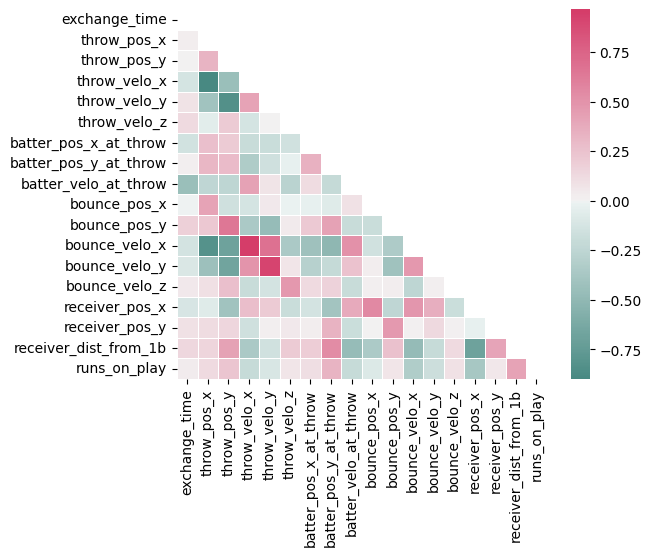

In [30]:
# Correlation matrix visualizaton for numeric features of interest
correlation_coefficients_df = fielder_throws_df[fielder_throws_numcols_list].corr()

# Generate a mask for the upper triangle using an array of the same size as correlation_coefficients_df of True Boolean values
mask = np.triu(np.ones_like(correlation_coefficients_df, dtype=bool))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(180, 0, as_cmap=True)

# Make the heatmap
sns.heatmap(correlation_coefficients_df, mask=mask, cmap=cmap, center=0, square=True, linewidths=0.5)

**Correlation Matrix Obseravtions:**
* Most of these features should have random relationships with one another. For example, the position where a throw is being made from should have no bearing on the position of the first baseman is since the first baseman should always be making their way to the base to make the play.
* `throw_velo_x` and `bounce_velo_x` appear to have strong negative correlations with `throw_pos_x`. This makes sense in baseball as the farther away from first base the fielder is (i.e., negative `throw_pos_x` values), the more they will put behind the throw resulting in a faster throw in an effort to reach first base quicker from a farther distance.
* If the throw bounces, the momemtum of the ball from the throw will cause it to still travel at a decent velocity, albeit reduced from the initial velocity when the throw is made. Hence, there are strong positive correlations between `bounce_velo_x-throw_velo_x` and `bounce_velo_y-throw_velo_y`.

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Outliers
Checking for and determining validity of outlier values in the numeric features of interest

Outliers are defined as values that are outside 1.5x the inner quartile range (IQR: range between the 25th and 75th percentile value).

In [31]:
# Use fielder_throws_described_df to calculate lower and upper bounds for outlier criteria for each numeric feature of interest
fielder_throws_described_df.loc['IQR'] = fielder_throws_described_df.loc['75%'] - fielder_throws_described_df.loc['25%']
fielder_throws_described_df.loc['lower_bound'] = fielder_throws_described_df.loc['25%'] - 1.5*fielder_throws_described_df.loc['IQR']
fielder_throws_described_df.loc['upper_bound'] = fielder_throws_described_df.loc['75%'] + 1.5*fielder_throws_described_df.loc['IQR']
fielder_throws_described_df

,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,bounce_pos_x,bounce_pos_y,bounce_velo_x,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,runs_on_play
count,19993.000000,19987.000000,19987.000000,19988.000000,19988.000000,19988.000000,19970.000000,19970.000000,19970.000000,1891.000000,1891.000000,1891.000000,1891.000000,1891.000000,19968.000000,19968.000000,19968.000000,20000.000000
mean,1.152051,-3.468916,116.136905,45.448197,-34.275720,8.295135,34.711631,36.754166,24.340806,42.334492,80.533757,23.838444,-22.774238,8.963900,59.332898,65.084216,5.935529,0.053050
std,0.518481,47.011863,40.898247,29.966971,26.683696,3.158743,9.864094,12.925644,4.931886,22.287096,19.173361,22.880595,14.542289,2.142547,10.797400,6.257555,11.880415,0.246452
min,0.000000,-214.106291,-35.301176,-73.745291,-102.139908,-17.642354,-77.459466,-8.614267,0.031605,-87.215484,-1.130720,-43.103385,-60.945206,-0.900142,-61.082994,-14.281589,0.037121,0.000000
25%,0.767000,-38.708315,93.806971,27.727906,-53.874025,6.480076,29.932345,30.527780,23.030804,31.314975,69.338822,11.400142,-32.706903,7.569747,60.058868,63.760289,2.588224,0.000000
50%,1.133000,-3.669111,122.060970,54.421747,-40.409015,8.273862,34.079170,34.759432,25.586250,47.041717,75.286643,30.961474,-23.531674,8.881996,60.874737,64.517151,3.202949,0.000000
75%,1.434000,25.505990,134.416408,68.593821,-17.485643,10.133839,38.860500,39.722379,27.310519,53.801463,86.965698,40.600469,-13.620749,10.190943,61.670060,65.481720,3.928205,0.000000
max,7.367000,225.873189,403.636958,92.651909,74.630702,28.497456,115.549679,130.170614,32.729044,131.297001,208.110588,63.304051,41.457148,22.303787,171.003787,178.908836,135.961657,3.000000
IQR,0.667000,64.214304,40.609437,40.865915,36.388382,3.653763,8.928155,9.194599,4.279715,22.486488,17.626877,29.200327,19.086154,2.621196,1.611192,1.721431,1.339981,0.000000
lower_bound,-0.233500,-135.029771,32.892816,-33.570966,-108.456599,0.999431,16.540113,16.735881,16.611232,-2.414758,42.898507,-32.400349,-61.336133,3.637954,57.642079,61.178142,0.578253,0.000000


Because there were very few cases where `runs_on_play` was greater than 0, its lower and upper bounds are calculated to be 0. However since run(s) scoring on a ground ball play is admissible, no `runs_on_play` values will be considered an outlier. `runs_on_play` will no longer be considered a numeric feature of interest. 

In [32]:
# Use bounds to count how many outliers exist in each numeric feature of interest
# Remove runs_on_play feature from numeric features of interest list
fielder_throws_numcols_list.remove('runs_on_play')

# Make a dictionary where the key-value pair is feature name-number of outliers detected in feature
feature_outliers_dict = {col: ((fielder_throws_df[col] < fielder_throws_described_df[col].loc['lower_bound'])
                                | (fielder_throws_df[col] > fielder_throws_described_df[col].loc['upper_bound'])).sum() for col in fielder_throws_numcols_list}
print(feature_outliers_dict)

{'exchange_time': 289, 'throw_pos_x': 323, 'throw_pos_y': 1108, 'throw_velo_x': 408, 'throw_velo_y': 342, 'throw_velo_z': 653, 'batter_pos_x_at_throw': 1172, 'batter_pos_y_at_throw': 1076, 'batter_velo_at_throw': 1152, 'bounce_pos_x': 105, 'bounce_pos_y': 132, 'bounce_velo_x': 17, 'bounce_velo_y': 25, 'bounce_velo_z': 40, 'receiver_pos_x': 1602, 'receiver_pos_y': 1363, 'receiver_dist_from_1b': 1570}


There were more outliers in the numeric features of interest than expected. However, outliers will be kept as they are without modification or removal because they can be from valid events during a baseball game (i.e., a `throw_velo_x` value could have been flagged as an outlier greater than the upper bound because it was from a player with a strong throwing arm that is well above league average or a `receiver_pos_x` value being flagged as an outlier when the fielder was actually positioned in that coordinate for defensive strategy). This data would be beneficial to not modify, limit, or remove when evaluating players and not lose from the dataset because it contains valuable information.

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)

### Position Coordinate Data Visualization
Plot positional data to see how it looks together to visualize the data in a baseball perpsective

In [33]:
# Get the feature names of positional coordinate data
fielder_throws_positional_list = list(filter(lambda col: 'pos' in col, fielder_throws_numcols_list))
fielder_throws_positional_list

['throw_pos_x',
 'throw_pos_y',
 'batter_pos_x_at_throw',
 'batter_pos_y_at_throw',
 'bounce_pos_x',
 'bounce_pos_y',
 'receiver_pos_x',
 'receiver_pos_y']

Text(0, 0.5, 'y (+ve is towards the outfield)')

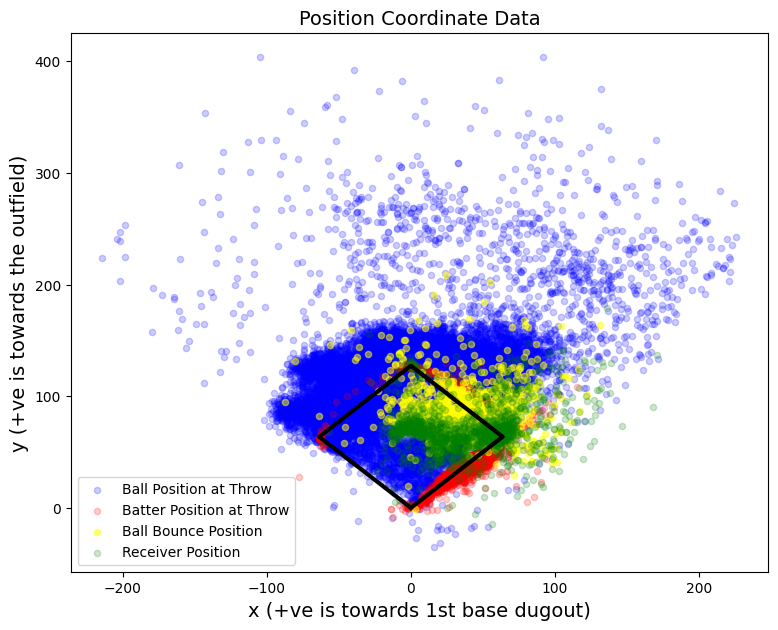

In [34]:
# Create the axes to plot all position coordinate data on the same plot
position_coordinate_figure, position_coordinate_axes = plt.subplots()

# Draw baselines
# Each side of a standard baseball baseline is 90ft thereby making it a sqaure
baseline_length = 90

# home plate tip is defined as (0,0)
x_home = 0
y_home = 0

# 1st base coordinates
# With home plate at (0,0), the horizontal and vertical distance between home plate and 1st base is equal to the x- and y-coordinates of 1st base respectively
# A 45 degree angle results between the 1st baseline and a horizontal at the tip of home plate since the 1st and 3rd baselines are perpendicular
x_1b = baseline_length*math.cos(math.radians(45))
y_1b = baseline_length*math.sin(math.radians(45))

# 2nd base coordinates
x_2b = 0 # because 2nd base is in line with home plate along the x-axis of the field
y_2b = 2*x_1b # because 2nd base is opposite of home plate and the same distance from 1st base and 3rd base as home plate is

# 3rd base coordinates
x_3b = -x_1b # like 1st base but to the left of home plate; reflected about the y-axis
y_3b = y_1b # in line with 1st base along y-axis

# plot baselines
position_coordinate_axes.plot([x_home, x_1b, x_2b, x_3b, x_home], [y_home, y_1b, y_2b, y_3b, y_home], color='black', linewidth=3)

# Plot position coordinate data
# Ball position at throw release
fielder_throws_df.plot.scatter(x='throw_pos_x', y='throw_pos_y', c='blue', alpha=0.2, ax=position_coordinate_axes, label='Ball Position at Throw', figsize=(9,7))

# Batter position at throw release
fielder_throws_df.plot.scatter(x='batter_pos_x_at_throw', y='batter_pos_y_at_throw', c='red', alpha=0.2, ax=position_coordinate_axes, label='Batter Position at Throw')

# If detected, ball bounce position
fielder_throws_df.plot.scatter(x='bounce_pos_x', y='bounce_pos_y', c='yellow', alpha=0.5, ax=position_coordinate_axes, label='Ball Bounce Position')

# Receiver position at throw release
fielder_throws_df.plot.scatter(x='receiver_pos_x', y='receiver_pos_y', c='green', alpha=0.2, ax=position_coordinate_axes, label='Receiver Position')

# Set plot labels
position_coordinate_axes.set_title('Position Coordinate Data', fontsize=14)
position_coordinate_axes.set_xlabel('x (+ve is towards 1st base dugout)', fontsize=14)
position_coordinate_axes.set_ylabel('y (+ve is towards the outfield)', fontsize=14)

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Exploratory-Data-Analysis)